# BC-04 w MLflow: powtórzenie porównania metod pod śledzeniem i parytet z notebookiem

## Metadata & Purpose

| | |
|---|---|
| **Autor** | agent AI, materiał szkoleniowy (dane syntetyczne) |
| **Data wykonania** | 2026-11-10; stan danych: 2026-09-20 |
| **Zespół** | Data Science, na zlecenie merchandisingu i działu cen i promocji Nordvik |
| **Zakres tej wersji** | E0–E4 zadania „BC-04: rozszerzenie MLflow”: setup, test klienta, konwencje, powtórzenie porównania, parytet, porównanie w kodzie i w UI. **Nie ma** jeszcze rejestru modelu, aliasów, konsumenta ani oceny tygodniowej (E5–E9) |

### Cel
1. Uruchomić serwer MLflow 3.5.0 i sprawdzić go z klienta (a nie tylko wewnątrz kontenera).
2. Powtórzyć porównanie metod z `bc04-sell-through-przecena.ipynb` jako **jedno uruchomienie na metodę** i sprawdzić, że liczby są identyczne z notebookiem.
3. Odtworzyć tabelę porównawczą z kodu, żeby inna osoba mogła ją obejrzeć w UI (`http://127.0.0.1:5000`).

### Decyzje i wyniki
Uzupełnione w sekcji *Results & Conclusions*. Notebook oryginalny i jego dane nie były zmieniane; jego kopia została wykonana osobno (`reference/`).

### Czego ten notebook nie robi
- Nie poprawia ani nie zmienia metod. Rejestr nie zwiększa mocy wniosków: za każdą liczbą stoi **66 modeli** z trzech zakończonych kolekcji.
- Komórki oznaczone **[wymaga serwera MLflow]** nie przejdą bez działającej usługi.

## Setup

**Po co:** wersje bibliotek i adres serwera w jednym miejscu. Wymaganie: wersja klienta MLflow = wersja serwera (3.5.0), bo różnica jest klasycznym źródłem niejasnych błędów. Adres tylko ze zmiennej `MLFLOW_TRACKING_URI`; w notebooku nie ma haseł.

In [1]:
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

import duckdb
import lightgbm
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
from mlflow import MlflowClient

sys.path.insert(0, str(Path("src").resolve()))
import bc04_core as core
import log_runs

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

URI = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
mlflow.set_tracking_uri(URI)
client = MlflowClient()
server_version = requests.get(URI + "/version", timeout=10).text.strip()  # [wymaga serwera MLflow]

print("Python", platform.python_version(), "|", platform.system())
for m in (mlflow, sklearn, lightgbm, pd, np, scipy, duckdb):
    print(f"{m.__name__:12s} {m.__version__}")
print("serwer MLflow:", server_version, "| adres:", URI)
assert server_version == mlflow.__version__, "wersja klienta różni się od wersji serwera"

Python 3.12.3 | Linux
mlflow       3.5.0
sklearn      1.9.1
lightgbm     4.7.0
pandas       2.3.3
numpy        2.5.4
scipy        1.18.1
duckdb       2.0.0
serwer MLflow: 3.5.0 | adres: http://127.0.0.1:5000


## Load Data

**Po co:** wczytuję tabelę modelową z rdzenia `src/bc04_core.py` (kod przeniesiony z notebooka BC-04 bez zmian logiki; dane z `datasets/synthetic/bc04/`, Parquet). Jedna wiersz to model w jednym momencie decyzji (końce tygodni 2–7 od pierwszej sprzedaży), bez 6 modeli przecenionych przed dniem 55 (ich etykieta byłaby zmieszana z rabatem). Wersję danych identyfikuje suma kontrolna plików.

In [2]:
DATA = Path(os.getenv("NORDVIK_BC04_DATA", "../../../datasets/synthetic/bc04")).resolve()
ds = core.build_dataset(DATA, Path("cache"))
D = ds.D
print(f"Loaded {len(D)} rows x {D.shape[1]} columns; modeli: {D.StyleCode.nunique()}; wszystkich (z cenzurowanymi): {ds.D_all.StyleCode.nunique()}")
display(D.head())
print("Modele czyste wg kolekcji:", D.groupby("Collection").StyleCode.nunique().to_dict())
print("Wersja danych (sha256 sześciu plików Parquet):", log_runs.data_version()[:16], "| kod:", log_runs.code_version())

Loaded 396 rows x 26 columns; modeli: 66; wszystkich (z cenzurowanymi): 72


,StyleCode,d,k,Collection,Category,first_disc_d,st_d,cum_d,supply_d,rate14,pred55,trend,avail_core,avail_all,restock,ln_price,p,c,cum55,supply55,st55,q_rest,censored,cat,mu3,s_fit
0,A-BAG-101,13,2,SS25,Akcesoria,63.0000,0.1196,597.0000,"4,991.0000",0.0085,0.4785,0.3680,1.0000,1.0000,0.0000,5.0863,161.7886,60.0300,"2,719.0000","4,991.0000",0.5448,"2,122.0000",False,0,0.3469,0.0745
1,A-BAG-102,13,2,SS25,Akcesoria,NaN,0.1948,647.0000,"3,321.0000",0.0139,0.7793,0.4545,1.0000,1.0000,0.0000,5.0863,161.7886,66.3000,"3,004.0000","4,167.0000",0.7209,"2,357.0000",False,0,0.5965,0.0804
2,A-BAG-103,13,2,SS25,Akcesoria,63.0000,0.1012,967.0000,"9,556.0000",0.0072,0.4048,0.1593,1.0000,1.0000,0.0000,5.2694,194.3089,68.2700,"4,425.0000","9,556.0000",0.4631,"3,458.0000",False,0,0.3225,0.0202
3,A-BAG-104,13,2,SS25,Akcesoria,NaN,0.1741,754.0000,"4,331.0000",0.0124,0.6964,-0.0212,1.0000,1.0000,0.0000,5.5263,251.2195,99.5200,"3,492.0000","4,331.0000",0.8063,"2,738.0000",False,0,0.5745,0.0428
4,A-BAG-105,13,2,SS26,Akcesoria,140.0000,0.2632,851.0000,"3,233.0000",0.0188,1.0000,0.0727,1.0000,1.0000,0.0000,5.2694,194.3089,78.1300,"2,725.0000","4,453.0000",0.6119,"1,874.0000",False,0,0.8561,0.0799


Modele czyste wg kolekcji: {'AW25': 22, 'SS25': 21, 'SS26': 23}
Wersja danych (sha256 sześciu plików Parquet): d04194d8bdf4936a | kod: {'git_commit': '312178c', 'core_sha256': 'eb7950e59f4aeca7'}


## Explore: diagnoza środowiska (E1) i liczby referencyjne (E0)

### Środowisko
Wnioski z rozpoznania (fakty):
- Repozytorium Nordvik nie zawiera `ds-ml-linux-setup/`; istnieje on poza repo (`~/infoshare-data-science-setup/ds-ml-linux-setup`) i **nie był edytowany**. Zestaw `core` (PostgreSQL + MLflow) uruchomiłem komendą `bash workshop.sh up core` (obraz `workshop-mlflow:3.5.0` był już zbudowany lokalnie).
- Stack był zatrzymany (kontenery `Exited` od 2 dni), a porty 5000 i 5432 były wolne. Zajęte były 8080 (Airflow BC-01) i 5433 (RetailDW), więc bez kolizji.
- Środowisko Pythona: w projekcie nie było żadnego (systemowy `python3` 3.12.3 miał tylko `pip`). Utworzyłem `mlflow/.venv`, zainstalowałem `mlflow==3.5.0` i zależności notebooka BC-04.

### Test z klienta (E1)
Skrypt `src/e1_client_check.py` loguje parametr, metrykę, artefakt (wykres) i mały model, a potem czyta je z serwera. Poniżej odczyt zapisanego wyniku z serwera **[wymaga serwera MLflow]**.

In [3]:
e1 = client.get_experiment_by_name("bc04-e1-test-klienta")
r1 = client.search_runs([e1.experiment_id], order_by=["attributes.start_time DESC"], max_results=1)[0]
print("run:", r1.info.run_name, "| status:", r1.info.status)
print("parametry:", r1.data.params, "| metryki:", r1.data.metrics)
print("artefakty:", [a.path for a in client.list_artifacts(r1.info.run_id)])
print("model zalogowany (sygnatura log_model w 3.5.0 przyjmuje `name=` obok `artifact_path`):", [m.name for m in client.search_logged_models([e1.experiment_id])])

run: e1-test | status: FINISHED
parametry: {'metoda': 'test'} | metryki: {'brier': 0.25}
artefakty: ['wykres.png']
model zalogowany (sygnatura log_model w 3.5.0 przyjmuje `name=` obok `artifact_path`): ['model']


In [4]:
try:
    out = subprocess.run(["docker", "ps", "--filter", "name=ds-workshop-(mlflow|postgres)", "--format", "{{.Names}}\t{{.Image}}\t{{.Status}}"],
                         capture_output=True, text=True, timeout=20)
    print(out.stdout or out.stderr)
except Exception as e:  # docker nie musi być dostępny z kernela
    print("docker niedostępny z kernela:", e)

ds-workshop-mlflow-1	f68fdb32b248	Up 8 minutes (healthy)
ds-workshop-postgres-1	7d0a41464797	Up 8 minutes (healthy)



### Liczby referencyjne (E0)
Źródło: **kopia** oryginalnego notebooka wykonana nieinteraktywnie (`src/run_reference.py`, katalog `reference/`), z dopisaną komórką zapisującą tabelę `tab6` i prognozy out-of-fold `O`. Oryginał nie został zmieniony. Brak `raportu-biznesowego.md` z poprzedniego zadania oraz `src/` — ich nie było w katalogu BC-04 (zapisane w dzienniku); referencją jest więc sam notebook (fazy 1–7.5; **fazy 8 z listą AW26 w notebooku jeszcze nie ma**).

In [5]:
ref = pd.read_csv("reference/ref_tab6.csv").set_index("metoda")
ref["modeli"] = D.StyleCode.nunique()
display(ref[["Brier", "Brier 90% od", "Brier 90% do", "log loss", "AUC", "koszt/wiersz (próg z walidacji)", "modeli"]].round(4))
print("Czas wykonania całego notebooka (kopia, bez cache):", Path("reference/elapsed_s.txt").read_text().strip(), "s")

,Brier,Brier 90% od,Brier 90% do,log loss,AUC,koszt/wiersz (próg z walidacji),modeli
metoda,,,,,,,
B0g,0.2925,0.2721,0.3112,0.7809,0.3106,"21,691.7060",66
B0,0.2762,0.2522,0.2972,0.7494,0.3571,"21,691.7060",66
B1,0.1177,0.0869,0.1497,0.4024,0.9178,"22,576.6296",66
B2,0.1219,0.0880,0.1589,0.4292,0.9125,"22,887.5836",66
M1a,0.1333,0.1039,0.1656,0.4657,0.8852,"20,420.6871",66
M1a bez avail_core,0.1333,0.1039,0.1656,0.4657,0.8852,"20,420.6871",66
M1a bez ln_price,0.1329,0.1032,0.1651,0.4640,0.8863,"20,574.7113",66
M1a bez restock,0.1337,0.1040,0.1669,0.4653,0.8834,"20,526.2319",66
M1r,0.1246,0.0971,0.1532,0.3972,0.9111,"21,378.5987",66


Czas wykonania całego notebooka (kopia, bez cache): 38.6 s


## Transform: specyfikacja i konwencje śledzenia (E0, E2)

**Metody (z poprzedniego zadania):** B0g, B0, B1, B2 (punkty odniesienia), M1a (metoda główna wskazana z góry w fazie 6), trzy ablacje M1a, M1r, M2 (+ Platt, + izotoniczna), M3. Dodatkowo cztery „polityki bez modelu” (nie flaguj nigdy / flaguj zawsze / praktyka robocza / reguła kosztowa EV), bo odpowiadają na pytanie biznesowe „czy to jest tańsze niż dziś”.

**Konwencje (każda odpowiada na pytanie audytora):**

| Element | Konwencja | Pytanie, na które odpowiada |
|---|---|---|
| Eksperyment | `bc04-sell-through-przecena` (test klienta osobno: `bc04-e1-test-klienta`) | gdzie leży porównanie, a gdzie test środowiska |
| Nazwa uruchomienia | `<metoda>__loco__<8 znaków sumy kontrolnej danych>` | która metoda, jaka walidacja, jaka wersja danych |
| Parametry | `method`, `features`, `hyperparameters`, `seed`, `tau`, `cost_*`, `decision_days`, `validation`, `bootstrap` | co dokładnie zostało uruchomione; założenia kosztowe widoczne dla audytora |
| Metryki | `brier`, `log_loss`, `auc`, `ece_5`, `cost_per_row_*` zbiorczo, z `*_ci90_*`, oraz `<metryka>__<kolekcja>`; liczebności `n_rows`, `n_models` (także per kolekcja) | jak dobra jest metoda i **ile modeli** stoi za liczbą |
| Artefakty | `calibration.png`, `oof_predictions.csv` (396 wierszy), `features.json`, `coefficients.csv` (tylko M1a, M1r) | można zobaczyć kalibrację i odtworzyć metryki bez uruchamiania kodu |
| Tagi | `data_version_sha256`, `git_commit`, `code_sha256_core`, `status`, `reason`, `suite_id`, `decision_days`, `scope`, `suite_elapsed_s` | która wersja danych i kodu, co jest kandydatem, a co punktem odniesienia |
| Zasada | jedno uruchomienie na metodę, bez zagnieżdżonych uruchomień i bez autologu | nie zaśmiecać rejestru setkami uruchomień z pętli walidacji |
| Czego nie logujemy | sekretów, zmiennych środowiskowych, surowych danych | wszystko w parametrach i tagach widzą wszyscy użytkownicy serwera |

**Czego świadomie nie rejestruję:** ślepych uliczek z dziennika poprzedniego zadania (brak kodu do ich odtworzenia, więc nie fabrykuję historii), wersji pośrednich oraz testów wrażliwości (próg 50/70%, scenariusze kosztów) — to osobne pytania, nie część porównania metod.

In [6]:
spec = pd.DataFrame({"cechy": {m: ", ".join(f) for m, f in core.FEATURES.items()}, "hiperparametry": core.HYPER, "status": {m: log_runs.STATUS[m] for m in core.METH}})
display(spec)
print("Stałe: seed =", core.SEED, "| tau =", core.TAU, "| koszty:", {k: v for k, v in core.COST.items() if k != "tau"}, "| momenty decyzji [dni]:", core.DAYS)

,cechy,hiperparametry,status
B0g,,brak,punkt_odniesienia
B0,Category,skurczenie n/(n+30) do częstości globalnej,punkt_odniesienia
B1,pred55,sigma_k z treningu; P=Phi((tau-pred55)/sigma_k),punkt_odniesienia
B2,"pred55, Category",korekta kategorii skurczona n/(n+30),punkt_odniesienia
M1a,"pred55, st_d, trend, avail_core, restock, ln_p...","LogisticRegression C=1, L2, StandardScaler",kandydat (metoda główna wskazana z góry)
M1a bez avail_core,"pred55, st_d, trend, restock, ln_price, k",jak M1a bez avail_core,ablacja
M1a bez ln_price,"pred55, st_d, trend, avail_core, restock, k",jak M1a bez ln_price,ablacja
M1a bez restock,"pred55, st_d, trend, avail_core, ln_price, k",jak M1a bez restock,ablacja
M1r,"pred55, st_d, trend, avail_core, restock, ln_p...","Ridge alpha=3 na st55, P=Phi((tau-mu)/sigma_k)",kandydat
M2,"pred55, st_d, trend, avail_core, restock, ln_p...",LGBM depth=2 leaves=4 n=150 lr=0.03 reg_lambda...,kandydat


Stałe: seed = 20260920 | tau = 0.6 | koszty: {'delta': 0.2, 'delta_clear': 0.25, 'hold_m': 0.015, 'hold_months': 2, 'eps': 0.5} | momenty decyzji [dni]: [13, 20, 27, 34, 41, 48]


## Analyze

### E3: uruchomienia pod śledzeniem
Logowanie wykonuje `src/log_runs.py` (jedno uruchomienie na metodę z pełną walidacją LOCO). Domyślnie **nie** uruchamiam go z notebooka, żeby „Restart & Run All” nie dokładał kolejnych duplikatów do rejestru; ustaw `RUN_LOGGING = True`, żeby zalogować nowy zestaw **[wymaga serwera MLflow]**. Poniżej wczytuję ostatni zalogowany zestaw (`suite_id`).

In [7]:
RUN_LOGGING = False
if RUN_LOGGING:
    subprocess.run([sys.executable, "src/log_runs.py"], check=True, env={**os.environ, "PYTHONPATH": "src"})

last = json.loads(Path("reference/last_suite.json").read_text())
runs = client.search_runs([client.get_experiment_by_name(last["experiment"]).experiment_id], filter_string=f"tags.suite_id = '{last['suite_id']}'")
RUNS = {r.data.params["method"]: r for r in runs}
print("suite_id:", last["suite_id"], "| uruchomień:", len(RUNS), "(metody:", len(core.METH), "+ polityki: 4)")
print("czas pełnego porównania (tag, dane i M3 z cache):", runs[0].data.tags["suite_elapsed_s"], "s")

suite_id: 460adf1d | uruchomień: 17 (metody: 13 + polityki: 4)
czas pełnego porównania (tag, dane i M3 z cache): 4.7 s


### Parytet z notebookiem

**Po co:** liczby w rejestrze muszą być identyczne z notebookiem (te same ziarna i wersje bibliotek). Rozbieżność byłaby wynikiem do zbadania, nie czymś do „dostrojenia”. Sprawdzam trzy rzeczy: (1) metryki zbiorcze z rejestru vs tabela `tab6` z kopii notebooka, (2) metryki per kolekcja z rejestru vs te same metryki policzone z `O` z kopii notebooka, (3) prognozy z artefaktów `oof_predictions.csv` vs kolumny `p__*` z `O` (0 = brak różnicy). Pełny zestaw sprawdzeń jest w `tests/test_parity.py`.

In [8]:
Oref = pd.read_parquet("reference/ref_O_final.parquet")
pairs = {"brier": "Brier", "log_loss": "log loss", "auc": "AUC", "ece_5": "ECE (5 przedziałów)", "cost_per_row_tuned": "koszt/wiersz (próg z walidacji)",
         "cost_per_row_theory": "koszt (próg teoretyczny)"}
rows = []
for m in core.METH:
    got = RUNS[m].data.metrics
    exp = log_runs.fold_metrics(Oref, m, core.TAU)  # te same wzory, ale na prognozach z kopii notebooka
    art = pd.read_csv(client.download_artifacts(RUNS[m].info.run_id, "oof_predictions.csv"))
    rows.append({"metoda": m,
                 "max |różnica| vs tab6 (zbiorczo)": max(abs(got[k] - TAB6) for k, TAB6 in ((k, ref.loc[m, c]) for k, c in pairs.items())),
                 "max |różnica| per kolekcja": max(abs(got[k] - v) for k, v in exp.items()),
                 "max |różnica| prognoz p": float(np.max(np.abs(art.p.to_numpy() - Oref["p__" + m].to_numpy())))})
parity = pd.DataFrame(rows).set_index("metoda")
display(parity.map(lambda v: f"{v:.1e}"))
print("Parytet pełny (wszystkie różnice < 1e-9):", bool((parity < 1e-9).all().all()))

,max |różnica| vs tab6 (zbiorczo),max |różnica| per kolekcja,max |różnica| prognoz p
metoda,,,
B0g,5.6e-17,0.0e+00,0.0e+00
B0,5.6e-17,0.0e+00,5.6e-17
B1,3.6e-12,0.0e+00,1.1e-16
B2,3.6e-12,0.0e+00,1.1e-16
M1a,3.6e-12,0.0e+00,1.1e-16
M1a bez avail_core,3.6e-12,0.0e+00,1.1e-16
M1a bez ln_price,5.6e-17,0.0e+00,1.1e-16
M1a bez restock,3.6e-12,0.0e+00,1.1e-16
M1r,5.6e-17,0.0e+00,1.1e-16


Parytet pełny (wszystkie różnice < 1e-9): True


In [9]:
res = subprocess.run([sys.executable, "-m", "pytest", "tests/test_parity.py", "-q", "-p", "no:cacheprovider"], capture_output=True, text=True, env={**os.environ, "MLFLOW_TRACKING_URI": URI})
print(res.stdout.strip().splitlines()[-1])

29 passed in 1.74s


### E4: tabela porównawcza z kodu (to samo, co zobaczy osoba w UI)

**Po co:** tabela z `mlflow.search_runs` odpowiada widokowi porównania uruchomień w UI (`Experiments → bc04-sell-through-przecena → Compare`). Przedziały to 90% bootstrapu po modelach. **Uwaga:** za każdą liczbą stoi **66 modeli** (396 wierszy model × moment), więc przedziały są szerokie i rankingu między metodami nie należy czytać dosłownie.

In [10]:
df = mlflow.search_runs(experiment_names=[last["experiment"]], filter_string=f"tags.suite_id = '{last['suite_id']}'")
tab = df.set_index("params.method")
cols = {"metrics.brier": "Brier", "metrics.brier_ci90_lo": "Brier 90% od", "metrics.brier_ci90_hi": "Brier 90% do", "metrics.log_loss": "log loss", "metrics.auc": "AUC",
        "metrics.cost_per_row_tuned": "koszt/wiersz [PLN]", "metrics.cost_tuned_ci90_lo": "koszt 90% od", "metrics.cost_tuned_ci90_hi": "koszt 90% do", "metrics.n_models": "modeli"}
cmp_ = tab[list(cols)].rename(columns=cols).join(tab["tags.status"].rename("status"))
display(cmp_.sort_values("Brier").round(4))

,Brier,Brier 90% od,Brier 90% do,log loss,AUC,koszt/wiersz [PLN],koszt 90% od,koszt 90% do,modeli,status
params.method,,,,,,,,,,
M2 + Platt,0.1108,0.0822,0.1411,0.3667,0.9084,"21,536.3759","14,262.0175","30,210.6527",66.0000,kandydat
M2,0.1128,0.0850,0.1410,0.3767,0.9076,"20,587.3126","13,483.7290","29,090.4176",66.0000,kandydat
M2 + izotoniczna,0.1161,0.0845,0.1488,0.3938,0.8765,"22,884.3801","15,373.5447","31,858.7616",66.0000,kandydat
B1,0.1177,0.0869,0.1497,0.4024,0.9178,"22,576.6296","14,887.0358","31,750.1082",66.0000,punkt_odniesienia
B2,0.1219,0.0880,0.1589,0.4292,0.9125,"22,887.5836","15,243.2585","32,027.6002",66.0000,punkt_odniesienia
M1r,0.1246,0.0971,0.1532,0.3972,0.9111,"21,378.5987","14,135.8065","29,899.0479",66.0000,kandydat
M1a bez ln_price,0.1329,0.1032,0.1651,0.4640,0.8863,"20,574.7113","13,463.1625","29,072.3321",66.0000,ablacja
M1a bez avail_core,0.1333,0.1039,0.1656,0.4657,0.8852,"20,420.6871","13,364.8104","28,940.0083",66.0000,ablacja
M1a,0.1333,0.1039,0.1656,0.4657,0.8852,"20,420.6871","13,364.8104","28,940.0083",66.0000,kandydat (metoda główna wskazana z góry)


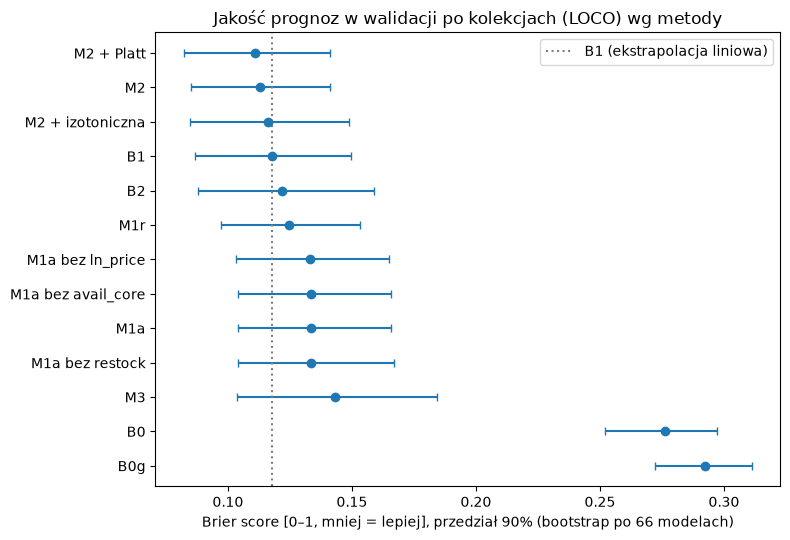

In [11]:
m_only = cmp_[cmp_.Brier.notna()].sort_values("Brier", ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(m_only))
ax.errorbar(m_only.Brier, y, xerr=[m_only.Brier - m_only["Brier 90% od"], m_only["Brier 90% do"] - m_only.Brier], fmt="o", capsize=3)
ax.set_yticks(y, m_only.index)
ax.axvline(m_only.loc["B1", "Brier"], color="gray", ls=":", label="B1 (ekstrapolacja liniowa)")
ax.set_xlabel("Brier score [0–1, mniej = lepiej], przedział 90% (bootstrap po 66 modelach)")
ax.set_title("Jakość prognoz w walidacji po kolekcjach (LOCO) wg metody")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
per_c = pd.DataFrame({m: {c: RUNS[m].data.metrics[f"brier__{c}"] for c in core.COLLS} for m in core.METH}).T
per_c["modeli w foldach"] = [" / ".join(str(int(RUNS[m].data.metrics[f"n_models__{c}"])) for c in core.COLLS) for m in core.METH]
print("Brier per kolekcja testowa (fold LOCO); ostatnia kolumna: liczba modeli SS25 / AW25 / SS26")
display(per_c.round(3))
pol = tab.loc[[n for n in tab.index if n not in core.METH], ["metrics.cost_per_row_tuned", "metrics.cost_tuned_ci90_lo", "metrics.cost_tuned_ci90_hi", "metrics.flag_share"]]
pol.columns = ["koszt/wiersz [PLN]", "90% od", "90% do", "udział flagowanych"]
print("Polityki bez modelu (koszt decyzji, założenia kosztowe z fazy 1.4 oryginału):")
display(pol.round(3).sort_values("koszt/wiersz [PLN]"))

Brier per kolekcja testowa (fold LOCO); ostatnia kolumna: liczba modeli SS25 / AW25 / SS26


,SS25,AW25,SS26,modeli w foldach
B0g,0.2530,0.3480,0.2760,21 / 22 / 23
B0,0.2360,0.3470,0.2450,21 / 22 / 23
B1,0.1170,0.1240,0.1130,21 / 22 / 23
B2,0.1190,0.1280,0.1190,21 / 22 / 23
M1a,0.1150,0.1580,0.1260,21 / 22 / 23
M1a bez avail_core,0.1150,0.1580,0.1260,21 / 22 / 23
M1a bez ln_price,0.1160,0.1570,0.1260,21 / 22 / 23
M1a bez restock,0.1160,0.1570,0.1280,21 / 22 / 23
M1r,0.1240,0.1290,0.1210,21 / 22 / 23
M2,0.0830,0.1580,0.0970,21 / 22 / 23


Polityki bez modelu (koszt decyzji, założenia kosztowe z fazy 1.4 oryginału):


,koszt/wiersz [PLN],90% od,90% do,udział flagowanych
params.method,,,,
reguła kosztowa EV (M1r),"20,871.9720","13,632.7000","29,699.8620",0.0300
nie flaguj nigdy,"21,691.7060","14,004.6130","30,895.9380",0.0000
praktyka robocza (ST < prosta do celu),"39,937.6710","30,485.8000","50,828.2090",0.5400
flaguj zawsze,"58,142.8240","50,068.3990","68,380.3200",1.0000


## Results & Conclusions

**Fakty (z tabel powyżej):**
- **Środowisko:** klient MLflow 3.5.0 = serwer 3.5.0; test z klienta (parametr, metryka, artefakt i model zapisane i odczytane) przeszedł za pierwszym razem, bez błędów nagłówka hosta ani wersji.
- **Parytet:** 13 metod odtworzonych zgodnie z kopią notebooka: cechy i prognozy `p` (różnica ≤ 1e-16), metryki per kolekcja (0), metryki zbiorcze (≤ 4e-12, błąd zaokrąglenia zapisu CSV); 29 testów w `tests/test_parity.py` przechodzi. Nie wystąpiła rozbieżność do wyjaśnienia.
- **Czas:** pełne porównanie (13 metod + 4 polityki, logowanie na serwer) ≈ 5 s przy gotowym cache M3; przy pustym cache dochodzi ok. 29 s na przygotowanie danych i dopasowania krzywych M3 (pomiar `check_core_parity.py`); cała kopia notebooka wykonuje się w ok. 39 s. Aktualizacja modelu po zakończeniu AW26 nie jest więc ograniczona czasem obliczeń.
- **Porównanie metod (H3 z oryginału, potwierdzone liczbami z rejestru):** najniższy Brier ma M2 + Platt (0,111), ale przedziały 90% prawie całkowicie się pokrywają ze wszystkimi metodami poza punktami odniesienia B0/B0g; B1 (ekstrapolacja liniowa, 0,118) jest statystycznie nieodróżnialny od M2 (0,113). Metoda główna wskazana z góry, M1a, ma Brier 0,133, czyli **gorszy** niż B1. Wniosek jest taki sam jak w notebooku BC-04 (faza 6): złożoność nie daje wyraźnej przewagi.
- **Per kolekcja:** w foldzie AW25 (jedyna zakończona kolekcja AW, 22 modele) M1a i M2 mają Brier 0,158, a B1 i M1r 0,124 i 0,129; w SS25 i SS26 M2 jest lepszy (0,083 i 0,097 wobec 0,117 i 0,113 dla B1). Przewaga M2 nie przenosi się więc na sezon AW, który dotyczy bieżącej kolekcji.
- **Koszt decyzji:** wszystkie reguły oparte na prognozie (ok. 20,4–22,9 tys. PLN na wiersz) mieszczą się w szumie wokół polityki „nie flaguj nigdy” (21,7 tys.); „flaguj zawsze” (58,1 tys.) i „praktyka robocza” (39,9 tys., to moje założenie o dzisiejszym postępowaniu) są wyraźnie droższe.

**Interpretacja (moja):** rejestr czyni wynik odtwarzalnym i audytowalnym, ale **nie zwiększa wiarygodności**: różnice między M2, B1, M1r i M3 mieszczą się w przedziałach, a próba to 66 modeli z jedną zakończoną kolekcją AW.

**Co zobaczy w UI dział cen bez znajomości kodu, a czego mu brakuje:**
- Widoczne: nazwy uruchomień (metoda), status (kandydat / ablacja / punkt odniesienia), Brier, log loss, AUC, koszt, liczba modeli, przedziały 90%, wykres kalibracji, tagi wersji danych i kodu.
- Brakuje: opisu metody prostym językiem (nazwy `B1`, `M2 + Platt` nic nie mówią; nie ustawiłem opisu uruchomienia), wyjaśnienia, że przedziały się pokrywają (UI pokazuje same wartości), informacji, że to 66 modeli i jedna zakończona kolekcja AW (jest w tagu `scope`, ale nie w kolumnie porównania), oraz jednego zdania, która metoda jest rekomendowana (decyzja z fazy 8 oryginału jeszcze nie istnieje).

**Rekomendacje:** (1) zweryfikować w UI tabelę porównania i wykresy kalibracji; (2) przed E5 (rejestr modelu) potwierdzić, którą metodę rekomendujemy: rekomendacja z fazy 8 oryginału nie powstała, a M1a (wskazana z góry) przegrywa z B1; (3) dopisać opisy uruchomień (`mlflow.note.content`) przed pokazaniem rejestru działowi cen.

## Appendix

### Dziennik pracy
- **Rozpoznanie.** Repozytorium bez `ds-ml-linux-setup/` i bez MLflow; zestaw znalazłem poza repo (`~/infoshare-data-science-setup`). Zmieniłem wcześniejszy plan „własny compose”: istniejący stack jest dokładnie tym środowiskiem, które opisuje zadanie (obraz 3.5.0, baza `mlflow` w PostgreSQL), więc użyłem go bez edycji plików.
- **Co zaskoczyło:** (1) systemowy Python bez żadnych pakietów, mimo że ktoś zakładał gotowe środowisko; (2) oryginalny katalog BC-04 zawiera tylko notebook, bez `src/`, `cache/` i raportu; (3) notebook kończy się na fazie 7.5, więc lista AW26 i rekomendacja nie istnieją.
- **Zmiana zdania:** przy pierwszej próbie uruchomienia kopii notebooka brakowało `nbformat` w używanym interpreterze (dwa różne terminale, jeden bez aktywnego venv); rozwiązanie: wywołania przez pełną ścieżkę do `.venv/bin/python`.
- **Weryfikacja przed logowaniem:** rdzeń `src/bc04_core.py` porównałem z kopią notebooka bez MLflow (cechy, prognozy wszystkich 13 metod, flaga EV: różnica 0), dopiero potem logowałem.
- **Zdarzenia środowiskowe:** czyszczenie `reference_run.log` z katalogu głównego repo (plik utworzony przez pomyłkę w złym katalogu przez moją komendę).

### Decyzje i odrzucone opcje
| Decyzja | Uzasadnienie | Odrzucone |
|---|---|---|
| Użyć istniejącego stacku workshop (`up core`), bez edycji | zgodne z zadaniem (3.5.0), zero ryzyka dla `databases/` | własny compose z osobnym Postgresem (duplikat) |
| Przenieść kod do `src/bc04_core.py`, oryginał bez zmian | zasada 2: nie zmieniam wyników poprzedniego zadania | importowanie z notebooka; edycja notebooka |
| Parytet na kopii wykonanej notebooka (`reference/`) | brak raportu z poprzedniego zadania; kopia daje liczby i prognozy do porównania | przepisanie liczb z ekranu |
| Jedno uruchomienie na metodę + 4 polityki, bez autologu | zasada E2; polityki odpowiadają na pytanie o koszt względem „dziś” | uruchomienia zagnieżdżone na foldy; przeszukiwanie hiperparametrów |
| Metody liczone osobno (`run_cv` per metoda) | czas per metoda; wynik identyczny jak razem (parytet 0) | jedna wspólna pętla |

### Pytania do zleceniodawcy (założenia robocze)
1. Którą metodę rekomendujemy do rejestru modelu: M1a (wskazana z góry, przegrywa z B1), B1 (prosta ekstrapolacja) czy M2 + Platt? *Robocze: decyzja po przeglądzie rejestru; faza 8 oryginału jeszcze nie powstała.*
2. Czy zakres momentów decyzji ma obejmować tydzień 7 (dzień 48)? *Robocze: tak, jak w tabeli modelowej oryginału; modele AW26 z transzy 31 sierpnia są poza zakresem.*
3. Czy próg 60% i założenia kosztowe z fazy 1.4 są akceptowalne? *Robocze: wartości z oryginału, zapisane jako parametry uruchomień.*
4. Kto zatwierdza zmianę aliasu modelu w przyszłości (E5–E9)? *Robocze: brak ustalenia.*

### Ograniczenia
- 66 modeli, jedna zakończona kolekcja AW; rejestr nie zmienia mocy wniosków.
- Środowisko szkoleniowe: jeden serwer, brak kontroli dostępu, publiczne poświadczenia, brak kopii zapasowych.
- Nie wykonano E5–E9 (rejestr modelu, aliasy, konsument w osobnym procesie, ocena tygodniowa, runbook, raport).
- Czas „pełnego porównania” przy pustym cache jest sumą dwóch pomiarów (dane + M3 ≈ 29 s oraz logowanie ≈ 5 s), a nie jednym pomiarem.
- Wersje: `mlflow` 3.5.0, `scikit-learn` 1.9.1, `lightgbm` 4.7.0, `pandas` 2.3.3, `numpy` 2.5.4, `scipy` 1.18.1, `duckdb` 2.0.0 (sekcja Setup drukuje aktualne wersje).